# PREDICCIÓN DEL PM2.5 HASTA 2030

## Evolución histórica de PM2,5

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
anual = spark.sql("""
    SELECT
        t.anio,
        ROUND(AVG(a.concentracion), 1) AS pm25_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t
        ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c
        ON a.id_contaminante = c.id_contaminante
    WHERE c.nombre = 'PM2.5'
        AND t.anio <= 2025
    GROUP BY t.anio
    ORDER BY t.anio
""").toPandas()

anual

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used
26/11/25 14:43:37 WARN YarnScheduler: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources


,anio,pm25_medio
0,2013,9.8
1,2014,10.1
2,2015,13.7
3,2016,10.7
4,2017,11.8
5,2018,14.3
6,2019,14.1
7,2020,10.5
8,2021,10.4
9,2022,11.5


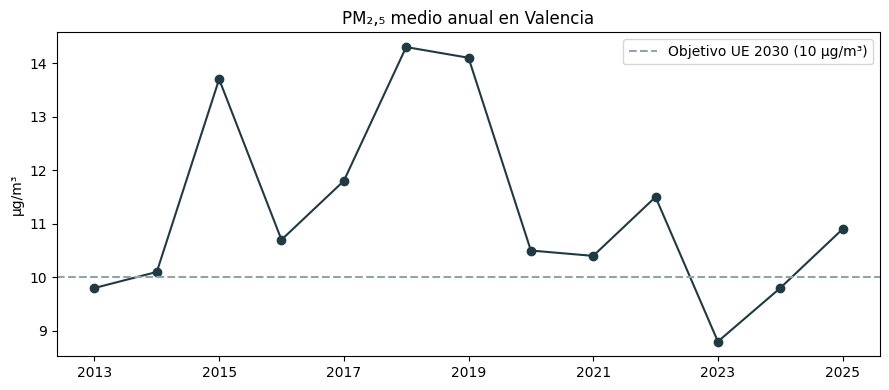

In [3]:
import matplotlib.pyplot as plt
from google.cloud import storage

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["pm25_medio"], marker="o", color="#203A43")
plt.axhline(10, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030 (10 µg/m³)")
plt.title("PM₂,₅ medio anual en Valencia")
plt.ylabel("µg/m³")
plt.xticks(range(2013, 2026, 2))
plt.legend()
plt.tight_layout()

plt.savefig("/tmp/pm25_evolucion_anual.png", dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/pm25_evolucion_anual.png"
).upload_from_filename("/tmp/pm25_evolucion_anual.png")

## Modelo de regresión lineal 

In [4]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# Datos de entrenamiento (excluimos 2020)
datos = anual[anual["anio"] != 2020]

# Entrenamos el modelo
modelo_lineal = LinearRegression()
modelo_lineal.fit(datos[["anio"]], datos["pm25_medio"])

print("Cambio por año:", round(modelo_lineal.coef_[0], 2), "µg/m³")

# Predicciones de 2026 a 2030
futuro = pd.DataFrame({"anio": range(2026, 2031)})
futuro["pm25_previsto"] = modelo_lineal.predict(futuro[["anio"]]).round(1)

futuro

/opt/conda/miniconda3/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.26.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Cambio por año: -0.1 µg/m³


,anio,pm25_previsto
0,2026,10.6
1,2027,10.5
2,2028,10.4
3,2029,10.3
4,2030,10.2


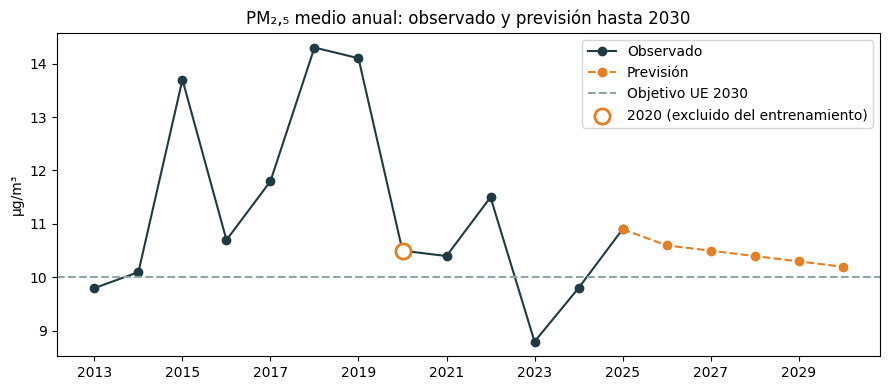

In [6]:
from google.cloud import storage

anios_pred = [2025] + futuro["anio"].tolist()
valores_pred = [anual.loc[anual["anio"] == 2025, "pm25_medio"].iloc[0]] + futuro["pm25_previsto"].tolist()

plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["pm25_medio"], marker="o", color="#203A43", label="Observado")
plt.plot(anios_pred, valores_pred, marker="o", linestyle="--", color="#E67E22", label="Previsión")
plt.axhline(10, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")

plt.scatter(anual.loc[anual["anio"] == 2020, "anio"],
            anual.loc[anual["anio"] == 2020, "pm25_medio"],
            s=120, facecolors="white", edgecolors="#E67E22",
            linewidths=2, zorder=3, label="2020 (excluido del entrenamiento)")

plt.title("PM₂,₅ medio anual: observado y previsión hasta 2030")
plt.ylabel("µg/m³")
plt.xticks(range(2013, 2031, 2))
plt.legend()
plt.tight_layout()
plt.savefig("/tmp/pm25_regresion_lineal.png", dpi=300, bbox_inches="tight")
plt.show()
storage.Client().bucket("tfm_unir1").blob(
    "figuras/pm25_regresion_lineal.png"
).upload_from_filename("/tmp/pm25_regresion_lineal.png")

## Evaluación del modelo de regresión lineal

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Entrenamiento y prueba
train_anual = anual[(anual["anio"] <= 2024) & (anual["anio"] != 2020)]
test_anual = anual[anual["anio"] == 2025]

modelo_test = LinearRegression()
modelo_test.fit(train_anual[["anio"]], train_anual["pm25_medio"])

prediccion_2025 = modelo_test.predict(test_anual[["anio"]])[0]
real_2025 = test_anual["pm25_medio"].iloc[0]

mae = mean_absolute_error([real_2025], [prediccion_2025])

print("Predicción 2025:", round(prediccion_2025, 1), "µg/m³")
print("Valor real 2025:", real_2025, "µg/m³")
print("MAE regresión lineal:", round(mae, 2), "µg/m³")

Predicción 2025: 10.7 µg/m³
Valor real 2025: 10.9 µg/m³
MAE regresión lineal: 0.25 µg/m³


## Modelo SARIMA mensual

In [8]:
mensual = spark.sql("""
    SELECT t.anio, t.mes,
           ROUND(AVG(a.concentracion), 1) AS pm25_medio
    FROM gold.fact_aire a
    JOIN gold.dim_tiempo t ON a.id_tiempo = t.id_tiempo
    JOIN gold.dim_contaminante c ON a.id_contaminante = c.id_contaminante
    WHERE c.nombre = 'PM2.5'
      AND t.anio BETWEEN 2013 AND 2025
    GROUP BY t.anio, t.mes
    ORDER BY t.anio, t.mes
""").toPandas()

mensual

,anio,mes,pm25_medio
0,2013,1,8.1
1,2013,2,8.2
2,2013,3,8.6
3,2013,4,11.3
4,2013,5,9.0
...,...,...,...
151,2025,8,14.5
152,2025,9,8.2
153,2025,10,8.9
154,2025,11,6.7


In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

mensual["fecha"] = pd.to_datetime(
    dict(year=mensual["anio"], month=mensual["mes"], day=1))

serie = mensual.set_index("fecha")["pm25_medio"].asfreq("MS")

print("Meses totales:", len(serie))
print("Meses sin datos:", serie.isna().sum())

train_mensual = serie.loc[:"2024-12-01"]
test_mensual = serie.loc["2025-01-01":]

Meses totales: 156
Meses sin datos: 0


## Comparación modelos SARIMA

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# Modelo de referencia: mismos meses de 2024
referencia = train_mensual.loc["2024-01-01":].values

# SARIMA A
modelo_a = SARIMAX(train_mensual,
    order=(1, 0, 0),seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pred_a = modelo_a.forecast(12)

# SARIMA B
modelo_b = SARIMAX(train_mensual,
    order=(0, 1, 1),seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pred_b = modelo_b.forecast(12)

# Comparación de errores durante 2025
for nombre, pred in [
    ("Referencia", referencia),
    ("SARIMA A", pred_a),
    ("SARIMA B", pred_b)
]:
    mae = mean_absolute_error(test_mensual, pred)
    mape = mean_absolute_percentage_error(test_mensual, pred) * 100
    print(nombre, "- MAE:", round(mae, 2),
          "µg/m³ | MAPE:", round(mape, 1), "%")

Referencia - MAE: 3.56 µg/m³ | MAPE: 32.6 %
SARIMA A - MAE: 2.72 µg/m³ | MAPE: 25.7 %
SARIMA B - MAE: 2.73 µg/m³ | MAPE: 25.9 %


## Predicción de PM2,5 hasta 2030

In [11]:
# Entrenamiento con todos los datos
final_a = SARIMAX(serie, order=(1, 0, 0),seasonal_order=(0, 1, 1, 12)
).fit(disp=False)

final_b = SARIMAX(serie, order=(0, 1, 1),seasonal_order=(0, 1, 1, 12)
).fit(disp=False)

# Predicciones de 2026 a 2030
prev_a = final_a.forecast(60)
prev_b = final_b.forecast(60)
print("Promedio de los 12 meses de 2030:")
print("SARIMA A:", round(prev_a["2030"].mean(), 1), "µg/m³")
print("SARIMA B:", round(prev_b["2030"].mean(), 1), "µg/m³")

# Intervalos de predicción del 95 %
intervalo_a = final_a.get_forecast(60).conf_int(alpha=0.05)
intervalo_b = final_b.get_forecast(60).conf_int(alpha=0.05)
for nombre, intervalo in [("SARIMA A", intervalo_a), ("SARIMA B", intervalo_b)]:
    print(nombre, "- Límites mensuales medios de 2030:",
          round(intervalo.loc["2030"].iloc[:, 0].mean(), 1),"a",
          round(intervalo.loc["2030"].iloc[:, 1].mean(), 1),"µg/m³")

Promedio de los 12 meses de 2030:
SARIMA A: 11.0 µg/m³
SARIMA B: 8.7 µg/m³
SARIMA A - Límites mensuales medios de 2030: 3.0 a 19.0 µg/m³
SARIMA B - Límites mensuales medios de 2030: -13.1 a 30.4 µg/m³


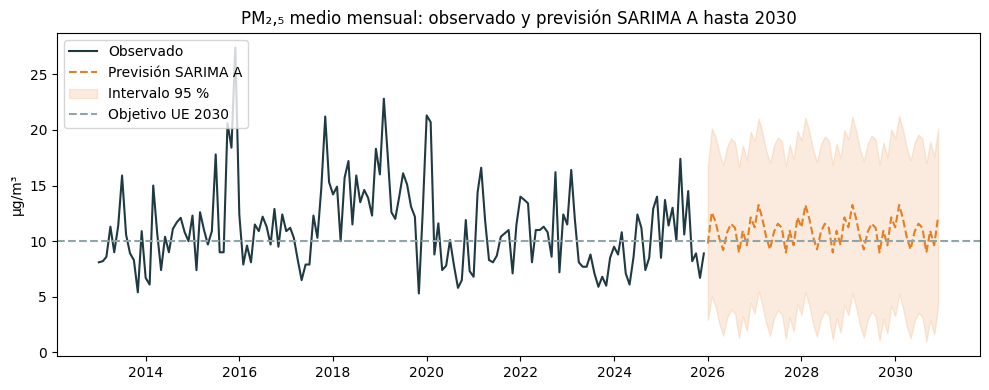

In [12]:
import matplotlib.pyplot as plt
from google.cloud import storage

plt.figure(figsize=(10, 4))
plt.plot(serie.index, serie, color="#203A43", label="Observado")
plt.plot(prev_a.index, prev_a, color="#E67E22", linestyle="--", label="Previsión SARIMA A")
plt.fill_between(intervalo_a.index, intervalo_a.iloc[:, 0], intervalo_a.iloc[:, 1],
                 color="#E67E22", alpha=0.15, label="Intervalo 95 %")
plt.axhline(10, color="#8FA5A8", linestyle="--", label="Objetivo UE 2030")
plt.title("PM₂,₅ medio mensual: observado y previsión SARIMA A hasta 2030")
plt.ylabel("µg/m³")
plt.legend()
plt.tight_layout()

plt.savefig("/tmp/pm25_sarima_2030.png", dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/pm25_sarima_2030.png"
).upload_from_filename("/tmp/pm25_sarima_2030.png")

## Guardar predicciones en la capa Gold

In [13]:
from datetime import date

# Regresión lineal: una previsión por año
tabla_lineal = pd.DataFrame({
    "modelo": "regresion_lineal",
    "indicador": "pm25",
    "horizonte": "2030",
    "granularidad": "anual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": pd.to_datetime(futuro["anio"].astype(str) + "-01-01").dt.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": futuro["pm25_previsto"],
    "valor_bajo": None,
    "valor_alto": None
})

# SARIMA A: una previsión por mes
prevision = final_a.get_forecast(60)
intervalo = prevision.conf_int(alpha=0.05)

tabla_sarima = pd.DataFrame({
    "modelo": "sarima_a",
    "indicador": "pm25",
    "horizonte": "2030",
    "granularidad": "mensual",
    "fecha_ejecucion": date.today(),
    "fecha_prevista": prev_a.index.date,
    "id_tiempo": None,
    "id_estacion": None,
    "valor_previsto": prev_a.round(1).values,
    "valor_bajo": intervalo.iloc[:, 0].round(1).values,
    "valor_alto": intervalo.iloc[:, 1].round(1).values
})

predicciones = pd.concat([tabla_lineal, tabla_sarima], ignore_index=True)

print("Total de predicciones:", len(predicciones))
predicciones.head(7)

Total de predicciones: 65


/tmp/ipykernel_4245/1045300649.py:36: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  predicciones = pd.concat([tabla_lineal, tabla_sarima], ignore_index=True)


,modelo,indicador,horizonte,granularidad,fecha_ejecucion,fecha_prevista,id_tiempo,id_estacion,valor_previsto,valor_bajo,valor_alto
0,regresion_lineal,pm25,2030,anual,2026-11-25,2026-01-01,None,None,10.6,NaN,NaN
1,regresion_lineal,pm25,2030,anual,2026-11-25,2027-01-01,None,None,10.5,NaN,NaN
2,regresion_lineal,pm25,2030,anual,2026-11-25,2028-01-01,None,None,10.4,NaN,NaN
3,regresion_lineal,pm25,2030,anual,2026-11-25,2029-01-01,None,None,10.3,NaN,NaN
4,regresion_lineal,pm25,2030,anual,2026-11-25,2030-01-01,None,None,10.2,NaN,NaN
5,sarima_a,pm25,2030,mensual,2026-11-25,2026-01-01,None,None,9.8,2.9,16.7
6,sarima_a,pm25,2030,mensual,2026-11-25,2026-02-01,None,None,12.6,5.1,20.1


In [15]:
pd.DataFrame.iteritems = pd.DataFrame.items

In [16]:
# Preparar los datos para Spark
datos_pred = predicciones.drop(columns=["id_tiempo", "id_estacion"])
spark.createDataFrame(datos_pred).createOrReplaceTempView("predicciones_pm25")

# Insertar en Gold
spark.sql("""
    INSERT INTO gold.fact_prediccion
    SELECT
        modelo,
        indicador,
        horizonte,
        granularidad,
        CAST(fecha_ejecucion AS DATE),
        CAST(fecha_prevista AS DATE),
        CAST(NULL AS INT) AS id_tiempo,
        CAST(NULL AS STRING) AS id_estacion,
        CAST(valor_previsto AS DOUBLE),
        CAST(valor_bajo AS DOUBLE),
        CAST(valor_alto AS DOUBLE),
        CAST(NULL AS INT) AS id_distrito
    FROM predicciones_pm25
""")

# Comprobar los registros guardados
spark.sql("""
    SELECT modelo, COUNT(*) AS registros
    FROM gold.fact_prediccion
    WHERE indicador = 'pm25'
    GROUP BY modelo
""").show()

26/11/25 15:01:20 WARN SessionState: METASTORE_FILTER_HOOK will be ignored, since hive.security.authorization.manager is set to instance of HiveAuthorizerFactory.


+----------------+---------+
|          modelo|registros|
+----------------+---------+
|        sarima_a|       60|
|regresion_lineal|        5|
+----------------+---------+

